# GRU with attention

Method-specific copy of `main.ipynb`, following the team's `main_<method>.ipynb` convention. The shared dataset loader, BIOES functions, decoder and evaluation functions below are copied unchanged from the template. GRU-specific data handling, architecture, training and evaluation follow them, with all implementation code visible in this notebook.

The existing trained run is loaded by default. Set `RUN_TRAINING=True` and choose a fresh `RUN_DIR` to train again. Existing weights, logs and predictions are preserved; reorganizing this notebook does not require retraining.

imports and global vars

In [1]:
from __future__ import annotations

import json, re, os, random, hashlib, platform, subprocess, time
from collections import Counter
from dataclasses import asdict, dataclass
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import torch
from torch import nn
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
from torch.nn.utils import clip_grad_norm_
from torch.utils import data
from torch.utils.data import DataLoader, Dataset
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

ROOT = Path.cwd().resolve()
if not (ROOT / "Data/data/en-US.jsonl").exists():
    ROOT = ROOT.parent
assert (ROOT / "Data/data/en-US.jsonl").exists(), "Run from the repository root or Source directory"
NOTEBOOK_PATH = ROOT / "Source/main_GRU_Attention.ipynb"
DATA_PATH = str(ROOT / "Data/data/en-US.jsonl")
SLOT_REGEX = re.compile(r"\[([^\[\]:]+)\s*:\s*([^\[\]]+)\]")
UNK_TOKEN = "<UNK>"
PAD_TOKEN = "<PAD>"
# GRU settings replace the template's example hyperparameters.
HIDDEN_SIZE = 128
NUM_EPOCHS = 40
BATCH_SIZE = 64
LEARNING_RATE = 0.003
EMBEDDING_DIM = 128
SAVE_DIR = str(ROOT / "Results/gru_attention")

load dataset functions

In [2]:
def parse_slots(annot_utt):
    # get list of (slot_type, slot_span) from annot_utt
    # turns the [color_type : pink] into ("color_type", "pink")
    return [(t.strip(), s.strip()) for t, s in SLOT_REGEX.findall(annot_utt)]

def load_massive(path=DATA_PATH):
    splits = {"train": [], "dev": [], "test": []}
    with open(path, encoding="utf-8") as f:
        for line in f:
            if not line.strip():
                continue
            r = json.loads(line)
            splits[r["partition"]].append({
                "id": r["id"],
                "scenario": r["scenario"],
                "intent": r["intent"],
                "utt": r["utt"],
                "annot_utt": r["annot_utt"],
                "slots": parse_slots(r["annot_utt"]),  
            })
    return splits

split the dataset

In [3]:
splits = load_massive()
expected = {"train": 11514, "dev": 2033, "test": 2974}
for k, n in expected.items():
    print(f"{k}: {len(splits[k])}")
    assert len(splits[k]) == n
assert sum(len(v) for v in splits.values()) == 16521

intents = sorted({r["intent"] for v in splits.values() for r in v})
slotTypes = sorted({t for v in splits.values() for r in v for t, _ in r["slots"]})
print("intents:", len(intents), "| slot types:", len(slotTypes))
print(splits["train"][1])

train: 11514
dev: 2033
test: 2974
intents: 60 | slot types: 55
{'id': '2', 'scenario': 'alarm', 'intent': 'alarm_set', 'utt': 'set an alarm for two hours from now', 'annot_utt': 'set an alarm for [time : two hours from now]', 'slots': [('time', 'two hours from now')]}


preprocessing data

going with BIOES tagging for the parts of the sentence

In [4]:
def annot_to_bioes(annot_utt):
    """Convert annotated text into tokens and BIOES tags."""
    # use whitespace to split, so just do utt.split()
    # then assign tags based on the slots
    # theres 55 slot types, so they will be tagged as B-time, I-time, B-house_place that kind
    # the 55 types are defined in the above cell

    tokens = []
    tags = []
    position = 0

    # Process each annotated slot, such as [time : five am]
    for match in SLOT_REGEX.finditer(annot_utt):

        # Words outside a slot are tagged as O
        outsideText = annot_utt[position:match.start()]

        for word in outsideText.split():
            tokens.append(word)
            tags.append("O")

        slotType = match.group(1).strip()
        words = match.group(2).split()

        # Assign BIOES tag for each word 
        for i, word in enumerate(words):
            if len(words) == 1:
                tag = f"S-{slotType}"
            elif i == 0:
                tag = f"B-{slotType}"
            elif i == len(words) - 1:
                tag = f"E-{slotType}"
            else:
                tag = f"I-{slotType}"

            tokens.append(word)
            tags.append(tag)

        position = match.end()

    # Process any remaining words after the last slot
    for word in annot_utt[position:].split():
        tokens.append(word)
        tags.append("O")

    return tokens, tags


def build_tag_vocab(records):

    slotTypes = sorted({
        slotType
        for record in records
        for slotType, _ in record["slots"]
    })

    tags = ["O"]

    for slotType in slotTypes:
        for prefix in ("B", "I", "E", "S"):
            tags.append(f"{prefix}-{slotType}")

    tagToId = {tag: i for i, tag in enumerate(tags)}

    return tags, tagToId


Decode the BIOES tags into (slot_type, slot_span)

In [5]:
def decode_bioes(tokens, tags):
    """Convert BIOES tags into a list of (slotType, slotSpan) pairs."""

    spans = []
    currentType = None
    currentTokens = []

    def closeSpan():
        nonlocal currentType, currentTokens

        if currentType is not None:
            slotText = " ".join(currentTokens)
            spans.append((currentType, slotText))

        currentType = None
        currentTokens = []

    for token, tag in zip(tokens, tags):

        if tag == "O":
            closeSpan()
            continue

        prefix, slotType = tag.split("-", 1)

        if prefix == "B":
            closeSpan()
            currentType = slotType
            currentTokens = [token]

        elif prefix == "I":
            if currentType == slotType:
                currentTokens.append(token)
            else:
                closeSpan()
                currentType = slotType
                currentTokens = [token]

        elif prefix == "E":
            if currentType == slotType:
                currentTokens.append(token)
                closeSpan()
            else:
                closeSpan()
                spans.append((slotType, token))

        elif prefix == "S":
            closeSpan()
            spans.append((slotType, token))

        else:
            closeSpan()

    # Include any unfinished span at the end
    closeSpan()

    return spans

Evaluation functions

In [6]:
def eval_intent_accuracy(actual, predicted):
    """Calculate the percentage of correctly predicted intents."""

    assert len(actual) == len(predicted)

    correctCount = sum(
        gold == pred
        for gold, pred in zip(actual, predicted)
    )

    return 100.0 * correctCount / len(actual)

def eval_macro_f1(actual, predicted):
    """Calculate micro F1 for slot types and spans across all utterances."""

    assert len(actual) == len(predicted)

    truePositives = 0
    falsePositives = 0
    falseNegatives = 0

    for act, pred in zip(actual, predicted):
        actualCount = Counter(act)
        predCount= Counter(pred)

        matchedCount = sum((actualCount & predCount).values())

        truePositives += matchedCount
        falsePositives += sum(predCount.values()) - matchedCount
        falseNegatives += sum(actualCount.values()) - matchedCount

    denominator = (
        2 * truePositives
        + falsePositives
        + falseNegatives
    )

    if denominator == 0:
        return 0.0

    return 100.0 * 2 * truePositives / denominator

def evaluate(goldIntents, predIntents, goldSlots, predSlots):
    """Calculate and return intent accuracy and slot F1."""

    intentAcc = round(eval_intent_accuracy(goldIntents, predIntents), 2)

    slotF1 = round(eval_macro_f1(goldSlots, predSlots), 2)

    return {
        "intent_acc": intentAcc,
        "slot_f1": slotF1,
    }

## GRU experiment configuration

The template function `eval_macro_f1` computes **slot micro F1**, pooled over exact `(slot type, slot span)` matches; its name is retained for team compatibility. We use the same shared functions below for preprocessing, decoding and scoring. The label inventories printed above describe the dataset; the model's vocabulary and label IDs are built from **train only**.

128-dimensional randomly initialized embeddings → one bidirectional GRU layer (128 hidden units per direction) → masked additive attention. The pooled context predicts the intent; token states concatenated with that context predict BIOES tags. No external task data or pretrained model is used.

Default: read the original seed-42 run. To train afresh, set `RUN_TRAINING=True` and change `RUN_DIR` to a new empty directory.

In [7]:
EXPECTED_COUNTS = {"train": 11514, "dev": 2033, "test": 2974}
PAD, UNK, IGNORE = 0, 1, -100
RUN_TRAINING = False
RUN_DIR = ROOT / "Results/gru_attention/seed_42"

@dataclass
class Config:
    seed: int = 42
    embedding_dim: int = 128
    hidden_size: int = 128  # per direction; a single bidirectional GRU layer
    attention_size: int = 128
    dropout: float = 0.3
    batch_size: int = 64
    learning_rate: float = 0.003
    weight_decay: float = 0.0001
    max_epochs: int = 40
    patience: int = 8
    threads: int = 4

config = Config(embedding_dim=EMBEDDING_DIM, hidden_size=HIDDEN_SIZE,
                batch_size=BATCH_SIZE, learning_rate=LEARNING_RATE,
                max_epochs=NUM_EPOCHS)
print(json.dumps(asdict(config), indent=2))

{
  "seed": 42,
  "embedding_dim": 128,
  "hidden_size": 128,
  "attention_size": 128,
  "dropout": 0.3,
  "batch_size": 64,
  "learning_rate": 0.003,
  "weight_decay": 0.0001,
  "max_epochs": 40,
  "patience": 8,
  "threads": 4
}


## GRU data preparation

Use the team's pre-separated `train.jsonl`, `dev.jsonl` and `test.jsonl`. Check them against the original source and shared loader; do not re-split or remove examples. Only `utt` supplies model inputs. Annotations supply labels; casing is retained for slot text and lowered only for word lookup.

In [8]:
def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def notebook_code_sha256(path):
    """Fingerprint code cells only, so executing/saving outputs preserves it."""
    document = json.loads(Path(path).read_text(encoding="utf-8"))
    code = "\n\n".join("".join(cell["source"]) if isinstance(cell["source"], list) else cell["source"]
                       for cell in document["cells"] if cell["cell_type"] == "code")
    return hashlib.sha256(code.encode("utf-8")).hexdigest()


def read_split(data_dir, split):
    path = Path(data_dir) / f"{split}.jsonl"
    with path.open(encoding="utf-8") as handle:
        rows = [json.loads(line) for line in handle if line.strip()]
    if len(rows) != EXPECTED_COUNTS[split]:
        raise ValueError(f"{split}: expected {EXPECTED_COUNTS[split]}, got {len(rows)}")
    if any(row["partition"] != split or row["locale"] != "en-US" for row in rows):
        raise ValueError(f"Incorrect partition or locale in {path}")
    return rows


def parse_annotation(annot_utt):
    """Use the template's BIOES conversion and slot parser for supervision."""
    tokens, tags = annot_to_bioes(annot_utt)
    slots = parse_slots(annot_utt)
    if not tokens or len(tokens) != len(tags):
        raise ValueError("Empty utterance or invalid annotation alignment")
    return tokens, tags, slots


def build_vocabs(train_rows):
    """Fit words, intents and BIOES label IDs on train only."""
    counts = Counter(token.lower() for row in train_rows for token in row["utt"].split())
    vocab = {"<PAD>": PAD, "<UNK>": UNK}
    for token, _ in sorted(counts.items(), key=lambda pair: (-pair[1], pair[0])):
        vocab[token] = len(vocab)
    records = [{**row, "slots": parse_slots(row["annot_utt"])} for row in train_rows]
    tags, _ = build_tag_vocab(records)
    intents = sorted({row["intent"] for row in train_rows})
    slot_types = sorted({kind for row in records for kind, _ in row["slots"]})
    return {"tokens": vocab, "intents": intents, "tags": tags, "slot_types": slot_types}


def audit_data(data_dir):
    splits = {name: read_split(data_dir, name) for name in EXPECTED_COUNTS}
    seen = set()
    report = {}
    for name, rows in splits.items():
        for row in rows:
            if row["id"] in seen:
                raise ValueError(f"Repeated ID across dataset: {row['id']}")
            seen.add(row["id"])
            tokens, tags, slots = parse_annotation(row["annot_utt"])
            if not tokens or tokens != row["utt"].split():
                raise ValueError(f"Annotation/utt alignment failed: {name}/{row['id']}")
            if Counter(decode_bioes(tokens, tags)) != Counter(slots):
                raise ValueError(f"Lossy slot conversion: {name}/{row['id']}")
        report[name] = {"examples": len(rows), "sha256": sha256(Path(data_dir) / f"{name}.jsonl")}
    # Compare split records to the original source rather than trusting counts alone.
    source = Path(data_dir) / "en-US.jsonl"
    if source.exists():
        with source.open(encoding="utf-8") as handle:
            original = [json.loads(line) for line in handle if line.strip()]
        if len(original) != sum(EXPECTED_COUNTS.values()):
            raise ValueError("Original source count differs from split total")
        if {r["id"]: r for r in original} != {r["id"]: r for rows in splits.values() for r in rows}:
            raise ValueError("Split records differ from original en-US.jsonl")
    vocabs = build_vocabs(splits["train"])
    if len(vocabs["intents"]) != 60 or len(vocabs["slot_types"]) != 55:
        raise ValueError("Expected all 60 intents and 55 slot types in train")
    train_tokens = vocabs["tokens"]
    for name, rows in splits.items():
        words = [w.lower() for row in rows for w in row["utt"].split()]
        report[name]["oov_token_pct"] = 100 * sum(w not in train_tokens for w in words) / len(words)
    return report, vocabs


class MassiveDataset(Dataset):
    def __init__(self, rows, vocabs):
        self.items = []
        intent_ids = {name: idx for idx, name in enumerate(vocabs["intents"])}
        tag_ids = {name: idx for idx, name in enumerate(vocabs["tags"])}
        for row in rows:
            tokens = row["utt"].split()  # sole source of model inputs
            aligned, tags, slots = parse_annotation(row["annot_utt"])
            if tokens != aligned or not tokens:
                raise ValueError(f"Annotation alignment failed for {row['id']}")
            self.items.append({
                "input_ids": torch.tensor([vocabs["tokens"].get(t.lower(), UNK) for t in tokens]),
                "tag_ids": torch.tensor([tag_ids[t] for t in tags]),
                "intent_id": intent_ids[row["intent"]],
                "id": row["id"], "utt": row["utt"], "tokens": tokens,
                "gold_intent": row["intent"], "gold_slots": slots,
            })

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):
        return self.items[index]


def collate(items):
    return {
        "input_ids": pad_sequence([r["input_ids"] for r in items], batch_first=True, padding_value=PAD),
        "tag_ids": pad_sequence([r["tag_ids"] for r in items], batch_first=True, padding_value=IGNORE),
        "lengths": torch.tensor([len(r["tokens"]) for r in items]),
        "intent_ids": torch.tensor([r["intent_id"] for r in items]),
        "items": items,
    }


def make_loader(rows, vocabs, config, shuffle=False):
    generator = torch.Generator().manual_seed(config.seed)
    return DataLoader(MassiveDataset(rows, vocabs), batch_size=config.batch_size,
                      shuffle=shuffle, collate_fn=collate, num_workers=0, generator=generator)

In [9]:
audit, vocabs = audit_data(ROOT / "Data/data")
print(json.dumps(audit, indent=2))
for name in EXPECTED_COUNTS:
    separated = read_split(ROOT / "Data/data", name)
    assert [(r["id"], r["utt"], r["intent"], r["annot_utt"]) for r in separated] == [
        (r["id"], r["utt"], r["intent"], r["annot_utt"]) for r in splits[name]]
print("Original loader and separated JSONL files match for all splits.")
print(f"Train vocabulary: {len(vocabs['tokens'])}; intents: {len(vocabs['intents'])}; slot types: {len(vocabs['slot_types'])}; tags: {len(vocabs['tags'])}")

{
  "train": {
    "examples": 11514,
    "sha256": "a626baa696fd107813cd953de529aba95a0daa658482e89f9e488c1e49ce6407",
    "oov_token_pct": 0.0
  },
  "dev": {
    "examples": 2033,
    "sha256": "61236c898d687f94b544fa361921fac96b34a26688a4ed1e0b935b4904ad7102",
    "oov_token_pct": 3.323306116602206
  },
  "test": {
    "examples": 2974,
    "sha256": "384fa7c4ae3e8d3b1223373662d84d9b44e665b2f5f7dc851457928f8c8bbc29",
    "oov_token_pct": 3.5145659782126484
  }
}
Original loader and separated JSONL files match for all splits.
Train vocabulary: 5304; intents: 60; slot types: 55; tags: 221


## GRU + attention model

Packed sequences prevent padding from affecting the bidirectional GRU. Attention normalizes over real tokens only. The two heads jointly predict the intent and BIOES slots. All layers are trained from scratch.

In [10]:
class GRUAttention(nn.Module):
    def __init__(self, vocab_size, intent_count, tag_count, config):
        super().__init__()
        width = 2 * config.hidden_size
        self.embedding = nn.Embedding(vocab_size, config.embedding_dim, padding_idx=PAD)
        self.dropout = nn.Dropout(config.dropout)
        self.gru = nn.GRU(config.embedding_dim, config.hidden_size, batch_first=True, bidirectional=True)
        self.attention = nn.Sequential(nn.Linear(width, config.attention_size), nn.Tanh(),
                                       nn.Linear(config.attention_size, 1, bias=False))
        self.intent_head = nn.Linear(width, intent_count)
        self.slot_head = nn.Sequential(nn.Linear(2 * width, config.hidden_size), nn.Tanh(),
                                       nn.Dropout(config.dropout), nn.Linear(config.hidden_size, tag_count))

    def forward(self, input_ids, lengths):
        embedded = self.dropout(self.embedding(input_ids))
        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        encoded, _ = self.gru(packed)
        hidden, _ = pad_packed_sequence(encoded, batch_first=True, total_length=input_ids.size(1))
        mask = torch.arange(input_ids.size(1), device=input_ids.device)[None, :] < lengths.to(input_ids.device)[:, None]
        energies = self.attention(hidden).squeeze(-1).masked_fill(~mask, float("-inf"))
        weights = energies.softmax(dim=1)
        context = torch.bmm(weights.unsqueeze(1), hidden).squeeze(1)
        intent_logits = self.intent_head(self.dropout(context))
        context_tokens = context.unsqueeze(1).expand(-1, hidden.size(1), -1)
        slot_logits = self.slot_head(self.dropout(torch.cat((hidden, context_tokens), dim=-1)))
        return intent_logits, slot_logits, weights

In [11]:
torch.manual_seed(config.seed)
model = GRUAttention(len(vocabs["tokens"]), len(vocabs["intents"]), len(vocabs["tags"]), config)
parameters = sum(p.numel() for p in model.parameters())
assert parameters <= 20_000_000
print(model)
print(f"Total and trainable parameters: {parameters:,}")

GRUAttention(
  (embedding): Embedding(5304, 128, padding_idx=0)
  (dropout): Dropout(p=0.3, inplace=False)
  (gru): GRU(128, 128, batch_first=True, bidirectional=True)
  (attention): Sequential(
    (0): Linear(in_features=256, out_features=128, bias=True)
    (1): Tanh()
    (2): Linear(in_features=128, out_features=1, bias=False)
  )
  (intent_head): Linear(in_features=256, out_features=60, bias=True)
  (slot_head): Sequential(
    (0): Linear(in_features=512, out_features=128, bias=True)
    (1): Tanh()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=128, out_features=221, bias=True)
  )
)
Total and trainable parameters: 1,019,673


## Training and evaluation implementation

Loss = intent cross entropy + non-padding slot-token cross entropy. AdamW starts at lr=0.003, weight decay=0.0001; dropout=0.3 and gradient clipping=5. Select the best checkpoint by the **unrounded mean** of validation intent accuracy and slot micro F1. Reduce LR on a validation plateau; stop after eight epochs without improvement, or at 40 epochs. The test set is scored only after checkpoint selection.

`score_predictions` calls the template's shared accuracy/F1 functions and adds diagnostic counts. The shared `decode_bioes` is used by training evaluation and raw-text inference.

In [12]:
def score_predictions(predictions):
    """Exact (type, surface-text) multiset matches, pooled across utterances.

    This matches main.ipynb, including duplicate slot pairs. Its eval_macro_f1
    function is actually micro F1; use the correct name here.
    """
    if not predictions:
        raise ValueError("Cannot score an empty split")
    correct = tp = fp = fn = joint = 0
    for row in predictions:
        gold, pred = Counter(map(tuple, row["gold_slots"])), Counter(map(tuple, row["pred_slots"]))
        match = sum((gold & pred).values())
        tp += match
        fp += sum(pred.values()) - match
        fn += sum(gold.values()) - match
        intent_ok = row["gold_intent"] == row["pred_intent"]
        correct += intent_ok
        joint += intent_ok and gold == pred
    precision = 100 * tp / (tp + fp) if tp + fp else 0.0
    recall = 100 * tp / (tp + fn) if tp + fn else 0.0
    return {
        "intent_accuracy": eval_intent_accuracy([r["gold_intent"] for r in predictions],
                                                [r["pred_intent"] for r in predictions]),
        "slot_micro_f1": eval_macro_f1([list(map(tuple, r["gold_slots"])) for r in predictions],
                                       [list(map(tuple, r["pred_slots"])) for r in predictions]),
        "slot_precision": precision,
        "slot_recall": recall,
        "joint_exact_match": 100 * joint / len(predictions),
        "slot_tp": tp, "slot_fp": fp, "slot_fn": fn,
        "examples": len(predictions),
    }


def run_epoch(model, loader, device, vocabs, optimizer=None):
    training = optimizer is not None
    model.train(training)
    intent_sum = slot_sum = examples = tokens = 0
    predictions = []
    with torch.set_grad_enabled(training):
        for batch in loader:
            inputs = batch["input_ids"].to(device)
            gold_intent = batch["intent_ids"].to(device)
            gold_tags = batch["tag_ids"].to(device)
            intent_logits, slot_logits, _ = model(inputs, batch["lengths"])
            intent_loss = nn.functional.cross_entropy(intent_logits, gold_intent)
            slot_loss = nn.functional.cross_entropy(slot_logits.reshape(-1, slot_logits.size(-1)),
                                                     gold_tags.reshape(-1), ignore_index=IGNORE)
            loss = intent_loss + slot_loss
            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite loss")
            if training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 5.0)
                optimizer.step()
            count = len(batch["items"])
            token_count = int(batch["lengths"].sum())
            intent_sum += intent_loss.item() * count
            slot_sum += slot_loss.item() * token_count
            examples += count
            tokens += token_count
            if not training:
                intent_ids = intent_logits.argmax(-1).cpu().tolist()
                tag_ids = slot_logits.argmax(-1).cpu().tolist()
                for row, intent_id, predicted in zip(batch["items"], intent_ids, tag_ids):
                    tags = [vocabs["tags"][idx] for idx in predicted[:len(row["tokens"])]]
                    predictions.append({
                        "id": row["id"], "utt": row["utt"], "tokens": row["tokens"],
                        "gold_intent": row["gold_intent"], "pred_intent": vocabs["intents"][intent_id],
                        "gold_slots": row["gold_slots"], "pred_slots": decode_bioes(row["tokens"], tags),
                        "pred_tags": tags,
                    })
    losses = {"intent_loss": intent_sum / examples, "slot_loss": slot_sum / tokens}
    losses["loss"] = losses["intent_loss"] + losses["slot_loss"]
    if not training:
        losses.update(score_predictions(predictions))
    return losses, predictions


def write_json(path, value):
    Path(path).write_text(json.dumps(value, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")


def load_checkpoint(path, device="cpu"):
    checkpoint = torch.load(path, map_location=device, weights_only=True)
    config, vocabs = Config(**checkpoint["config"]), checkpoint["vocabs"]
    model = GRUAttention(len(vocabs["tokens"]), len(vocabs["intents"]), len(vocabs["tags"]), config).to(device)
    model.load_state_dict(checkpoint["model_state"])
    model.eval()
    return model, vocabs, config, checkpoint


def predict(utterance, checkpoint_path):
    """Inference requires only raw utt and the saved checkpoint."""
    tokens = utterance.split()
    if not tokens:
        raise ValueError("Utterance cannot be blank")
    model, vocabs, config, _ = load_checkpoint(checkpoint_path)
    torch.set_num_threads(config.threads)
    inputs = torch.tensor([[vocabs["tokens"].get(t.lower(), UNK) for t in tokens]])
    with torch.inference_mode():
        intent, slots, attention = model(inputs, torch.tensor([len(tokens)]))
    tags = [vocabs["tags"][idx] for idx in slots[0].argmax(-1).tolist()]
    return {"utt": utterance, "intent": vocabs["intents"][intent.argmax(-1).item()],
            "slots": decode_bioes(tokens, tags), "tokens": tokens,
            "attention": attention[0].tolist()}


def plot_history(history, output):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    epochs = [r["epoch"] for r in history]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(epochs, [r["train"]["loss"] for r in history], label="Train")
    axes[0].plot(epochs, [r["dev"]["loss"] for r in history], label="Validation")
    axes[0].set(ylabel="Intent CE + token slot CE", xlabel="Epoch", title="GRU + attention: loss")
    for key, label in (("intent_accuracy", "Intent accuracy"), ("slot_micro_f1", "Slot micro F1")):
        axes[1].plot(epochs, [r["dev"][key] for r in history], label=label)
    axes[1].set(xlabel="Epoch", ylabel="Percent", title="Validation metrics")
    for axis in axes:
        axis.grid(alpha=0.25)
        axis.legend()
    fig.tight_layout()
    fig.savefig(Path(output) / "learning_curves.png", dpi=160)
    plt.close(fig)

In [13]:
def train(config=None, data_dir=None, output_dir=None):
    config = config or Config()
    data_dir = Path(data_dir or ROOT / "Data/data").resolve()
    output = Path(output_dir or ROOT / "Results/gru_attention/seed_42").resolve()
    # A second run must not overwrite a completed baseline or its test evaluation.
    if output.exists() and any(output.iterdir()):
        raise FileExistsError(f"Output directory is nonempty; choose a fresh --output-dir: {output}")
    output.mkdir(parents=True, exist_ok=True)
    random.seed(config.seed)
    np.random.seed(config.seed)
    torch.manual_seed(config.seed)
    torch.set_num_threads(config.threads)
    torch.use_deterministic_algorithms(True)
    device = torch.device("cpu")
    audit, vocabs = audit_data(data_dir)
    write_json(output / "data_audit.json", audit)
    write_json(output / "vocabs.json", vocabs)
    write_json(output / "config.json", asdict(config))
    train_loader = make_loader(read_split(data_dir, "train"), vocabs, config, shuffle=True)
    dev_loader = make_loader(read_split(data_dir, "dev"), vocabs, config)
    model = GRUAttention(len(vocabs["tokens"]), len(vocabs["intents"]), len(vocabs["tags"]), config).to(device)
    parameters = sum(p.numel() for p in model.parameters())
    if parameters > 20_000_000:
        raise ValueError(f"Parameter budget exceeded: {parameters}")
    optimizer = torch.optim.AdamW(model.parameters(), lr=config.learning_rate, weight_decay=config.weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)
    commit = subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=ROOT, text=True).strip()
    environment = {
        "python": platform.python_version(), "torch": str(torch.__version__), "numpy": np.__version__,
        "platform": platform.platform(), "device": str(device), "threads": config.threads,
        "git_base_commit": commit, "source_sha256": notebook_code_sha256(NOTEBOOK_PATH),
        "source_file": NOTEBOOK_PATH.name, "source_kind": "notebook_code",
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
    }
    write_json(output / "environment.json", environment)
    checkpoint_path = output / "best.pt"
    history, best_score, best_epoch = [], -float("inf"), 0
    started = time.perf_counter()
    log_path = output / "training.log"

    def log(message):
        print(message, flush=True)
        with log_path.open("a", encoding="utf-8") as handle:
            handle.write(message + "\n")

    log(f"GRU + attention baseline | base {commit} | device {device} | seed {config.seed}")
    log(f"Splits: {EXPECTED_COUNTS} | vocab {len(vocabs['tokens'])} | intents 60 | tags {len(vocabs['tags'])}")
    log(f"Parameters: {parameters:,} / 20,000,000 | selection: mean(dev intent accuracy, dev slot micro F1)")
    for epoch in range(1, config.max_epochs + 1):
        epoch_start = time.perf_counter()
        lr = optimizer.param_groups[0]["lr"]
        train_metrics, _ = run_epoch(model, train_loader, device, vocabs, optimizer)
        dev_metrics, _ = run_epoch(model, dev_loader, device, vocabs)
        score = (dev_metrics["intent_accuracy"] + dev_metrics["slot_micro_f1"]) / 2
        history.append({"epoch": epoch, "learning_rate": lr, "train": train_metrics, "dev": dev_metrics,
                        "selection_score": score, "epoch_seconds": time.perf_counter() - epoch_start,
                        "elapsed_seconds": time.perf_counter() - started})
        improved = score > best_score
        if improved:
            best_score, best_epoch = score, epoch
            torch.save({"model_state": model.state_dict(), "config": asdict(config), "vocabs": vocabs,
                        "epoch": epoch, "selection_score": score, "dev_metrics": dev_metrics,
                        "parameter_count": parameters, "environment": environment}, checkpoint_path)
        write_json(output / "history.json", history)
        log(f"epoch {epoch:02d} | train loss {train_metrics['loss']:.4f} | dev loss {dev_metrics['loss']:.4f} | "
            f"dev intent {dev_metrics['intent_accuracy']:.2f}% | dev slot F1 {dev_metrics['slot_micro_f1']:.2f}% | "
            f"mean {score:.2f} | lr {lr:g} | {history[-1]['epoch_seconds']:.1f}s" + (" | saved best" if improved else ""))
        scheduler.step(score)
        if epoch - best_epoch >= config.patience:
            log(f"Early stopping: {config.patience} epochs without validation improvement")
            break
    # Freeze selection before loading the test split for final evaluation.
    model, _, _, checkpoint = load_checkpoint(checkpoint_path, device)
    dev_metrics, dev_predictions = run_epoch(model, dev_loader, device, vocabs)
    for key in ("intent_accuracy", "slot_micro_f1", "loss"):
        if abs(dev_metrics[key] - checkpoint["dev_metrics"][key]) > 1e-6:
            raise AssertionError(f"Reloaded checkpoint validation mismatch: {key}")
    test_loader = make_loader(read_split(data_dir, "test"), vocabs, config)
    test_metrics, test_predictions = run_epoch(model, test_loader, device, vocabs)
    for name, predictions in (("dev", dev_predictions), ("test", test_predictions)):
        with (output / f"{name}_predictions.jsonl").open("w", encoding="utf-8") as handle:
            for row in predictions:
                handle.write(json.dumps(row, ensure_ascii=False) + "\n")
    result = {
        "model": "BiGRU + masked additive attention (joint intent and BIOES slots)",
        "parameter_count": parameters, "trainable_parameter_count": parameters,
        "best_epoch": best_epoch, "epochs_trained": len(history), "seed": config.seed,
        "selection_metric": "arithmetic mean of dev intent accuracy and dev slot micro F1 (percent)",
        "best_selection_score": best_score, "checkpoint": "best.pt", "checkpoint_sha256": sha256(checkpoint_path),
        "training_seconds": history[-1]["elapsed_seconds"], "total_seconds": time.perf_counter() - started,
        "dev": dev_metrics, "test": test_metrics, "environment": environment,
        "test_evaluations_during_selection": 0,
    }
    write_json(output / "metrics.json", result)
    plot_history(history, output)
    lines = ["# GRU + attention baseline", "",
             f"Base commit: `{commit}`. Seed: {config.seed}. CPU. Parameters: {parameters:,}.",
             f"Selected epoch {best_epoch} of {len(history)} by mean validation intent accuracy / slot micro F1.", "",
             "| Split | Intent accuracy (%) | Slot micro F1 (%) |", "| --- | ---: | ---: |"]
    for name, metrics in (("Validation", dev_metrics), ("Test", test_metrics)):
        lines.append(f"| {name} | {metrics['intent_accuracy']:.2f} | {metrics['slot_micro_f1']:.2f} |")
    lines += ["", "The test split was evaluated only after checkpoint selection. Vocabularies use train only.",
              "Slot scoring uses exact (type, span-text) multiset matches, identical to Source/main.ipynb.",
              "All metrics in metrics.json retain full precision; table values are percentages rounded to two decimals.",
              "", f"Training time: {result['training_seconds']:.1f} seconds.",
              "", "Artifacts: best.pt, config.json, vocabs.json, data_audit.json, environment.json, history.json,",
              "training.log, dev_predictions.jsonl, test_predictions.jsonl, metrics.json, learning_curves.png."]
    (output / "README.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
    log(f"Best epoch {best_epoch} | score {best_score:.2f} | checkpoint {checkpoint_path}")
    log(f"Final validation: intent {dev_metrics['intent_accuracy']:.2f}% | slot micro F1 {dev_metrics['slot_micro_f1']:.2f}%")
    log(f"Final test: intent {test_metrics['intent_accuracy']:.2f}% | slot micro F1 {test_metrics['slot_micro_f1']:.2f}%")
    return result

## Run training or read the saved experiment

With the default `RUN_TRAINING=False`, this cell reads the existing log and checks the saved artifacts. It does not run training again. Those logs were produced by the original CLI implementation; its recorded source hash and run metadata are retained. Fresh notebook runs record a fingerprint of this notebook's code cells, independent of saved outputs.

In [14]:
if RUN_TRAINING:
    train(config, ROOT / "Data/data", RUN_DIR)
assert (RUN_DIR / "metrics.json").exists(), "Run training in a new directory, or select an existing completed RUN_DIR"
metrics = json.loads((RUN_DIR / "metrics.json").read_text(encoding="utf-8"))
history = json.loads((RUN_DIR / "history.json").read_text(encoding="utf-8"))
assert metrics["checkpoint_sha256"] == sha256(RUN_DIR / "best.pt")
recorded_audit = json.loads((RUN_DIR / "data_audit.json").read_text(encoding="utf-8"))
for split in EXPECTED_COUNTS:
    assert audit[split]["examples"] == recorded_audit[split]["examples"]
    assert audit[split]["oov_token_pct"] == recorded_audit[split]["oov_token_pct"]
    raw = (ROOT / "Data/data" / f"{split}.jsonl").read_bytes()
    lf = raw.replace(b"\r\n", b"\n")
    # Git may check out LF or CRLF. Require identical content under either ending.
    allowed_hashes = {hashlib.sha256(value).hexdigest() for value in (raw, lf, lf.replace(b"\n", b"\r\n"))}
    assert recorded_audit[split]["sha256"] in allowed_hashes, split
assert asdict(config) == json.loads((RUN_DIR / "config.json").read_text(encoding="utf-8"))
if metrics["environment"].get("source_kind") == "notebook_code":
    assert metrics["environment"]["source_sha256"] == notebook_code_sha256(NOTEBOOK_PATH)
else:
    print("Reading original CLI run; historical source SHA-256:", metrics["environment"].get("training_source_sha256", metrics["environment"].get("source_sha256")))
print((RUN_DIR / "training.log").read_text(encoding="utf-8"))
print(f"Selected epoch {metrics['best_epoch']} of {metrics['epochs_trained']}; data and checkpoint hashes verified.")

Reading original CLI run; historical source SHA-256: d3fbed81f002068deee1c746bb00b86976e01d498a21eda0467def1a4e6171fd
GRU + attention baseline | base 199b0c111b745b3dbf1a9f093ea05f1a2f23105a | device cpu | seed 42
Splits: {'train': 11514, 'dev': 2033, 'test': 2974} | vocab 5304 | intents 60 | tags 221
Parameters: 1,019,673 / 20,000,000 | selection: mean(dev intent accuracy, dev slot micro F1)
epoch 01 | train loss 3.6290 | dev loss 2.0173 | dev intent 72.90% | dev slot F1 23.35% | mean 48.12 | lr 0.003 | 14.4s | saved best
epoch 02 | train loss 1.9028 | dev loss 1.4699 | dev intent 79.29% | dev slot F1 45.39% | mean 62.34 | lr 0.003 | 13.2s | saved best
epoch 03 | train loss 1.4647 | dev loss 1.2928 | dev intent 80.91% | dev slot F1 50.13% | mean 65.52 | lr 0.003 | 14.6s | saved best
epoch 04 | train loss 1.2175 | dev loss 1.2107 | dev intent 82.44% | dev slot F1 54.19% | mean 68.32 | lr 0.003 | 16.7s | saved best
epoch 05 | train loss 1.0522 | dev loss 1.1886 | dev intent 82.83% | dev

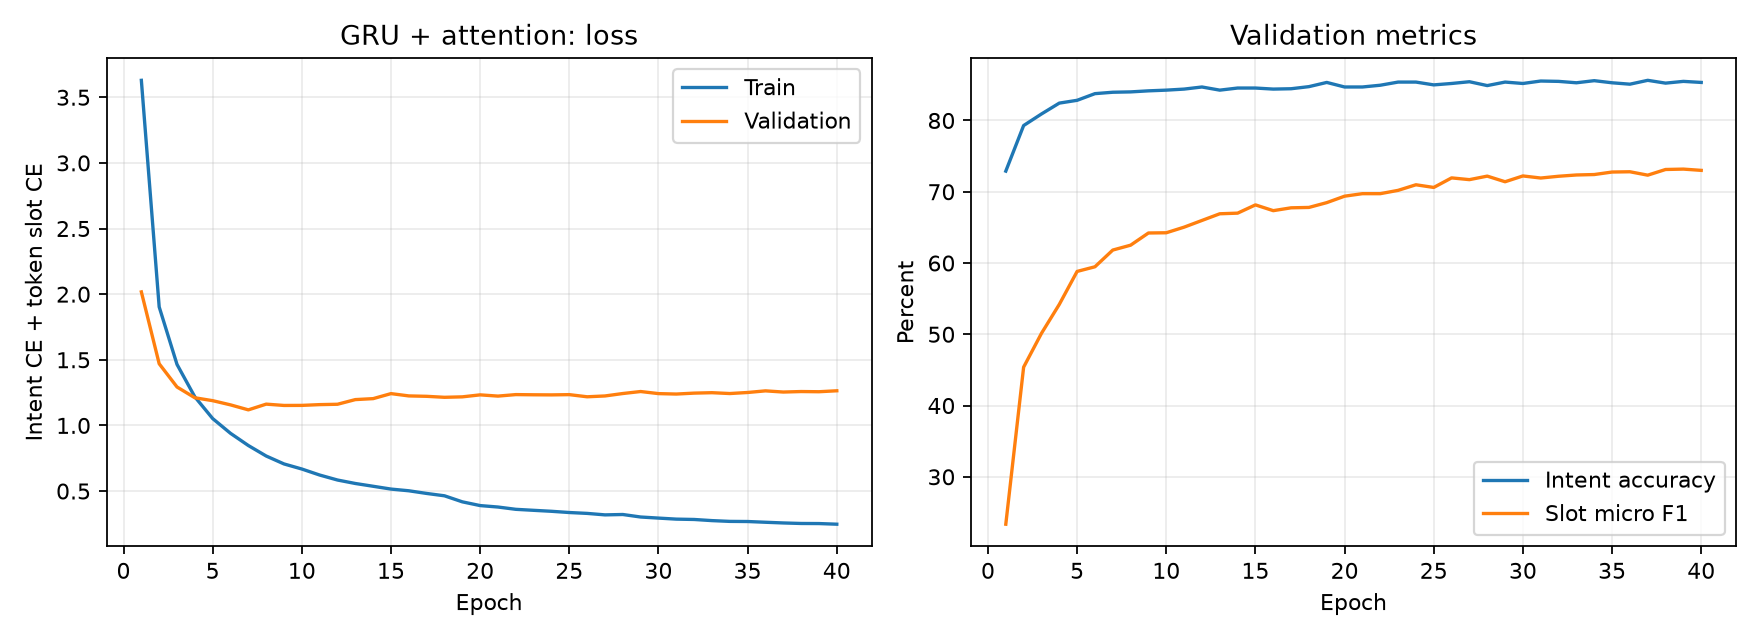

In [15]:
display(Image(filename=str(RUN_DIR / "learning_curves.png")))

## Final results using the team's shared functions

Recompute the existing saved dev/test predictions using `evaluate` from the template. These are exact `(slot type, span text)` micro-F1 scores, even though the shared function is named `eval_macro_f1`. Values are shown as percentages with two decimal places.

Check that the saved checkpoint gives the same validation metrics with the inline model, data adapter, shared decoder and shared scorer. This validation-only check confirms that the reorganization preserves model behavior; test predictions are read from the frozen run.

In [16]:
table = ["| Split | Intent accuracy (%) | Slot micro F1 (%) |", "| --- | ---: | ---: |"]
for split in ("dev", "test"):
    predictions = [json.loads(line) for line in (RUN_DIR / f"{split}_predictions.jsonl").read_text(encoding="utf-8").splitlines()]
    assert [r["id"] for r in predictions] == [r["id"] for r in splits[split]]
    gold_intents = [r["gold_intent"] for r in predictions]
    pred_intents = [r["pred_intent"] for r in predictions]
    gold_slots = [list(map(tuple, r["gold_slots"])) for r in predictions]
    pred_slots = [list(map(tuple, r["pred_slots"])) for r in predictions]
    for original, predicted in zip(splits[split], predictions):
        assert original["utt"] == predicted["utt"]
        assert original["intent"] == predicted["gold_intent"]
        assert Counter(original["slots"]) == Counter(map(tuple, predicted["gold_slots"]))
        assert Counter(decode_bioes(predicted["tokens"], predicted["pred_tags"])) == Counter(map(tuple, predicted["pred_slots"]))
    shared_scores = evaluate(gold_intents, pred_intents, gold_slots, pred_slots)
    recomputed = score_predictions(predictions)
    for key, value in recomputed.items():
        assert abs(value - metrics[split][key]) < 1e-10, (split, key)
    assert shared_scores["intent_acc"] == round(metrics[split]["intent_accuracy"], 2)
    assert shared_scores["slot_f1"] == round(metrics[split]["slot_micro_f1"], 2)
    table.append(f"| {split} | {shared_scores['intent_acc']:.2f} | {shared_scores['slot_f1']:.2f} |")
best = max(history, key=lambda row: row["selection_score"])
assert best["epoch"] == metrics["best_epoch"]
assert best["dev"]["intent_accuracy"] == metrics["dev"]["intent_accuracy"]
assert best["dev"]["slot_micro_f1"] == metrics["dev"]["slot_micro_f1"]
assert metrics["test_evaluations_during_selection"] == 0

torch.set_num_threads(config.threads)
model, saved_vocabs, saved_config, checkpoint = load_checkpoint(RUN_DIR / "best.pt")
assert saved_vocabs == vocabs and asdict(saved_config) == asdict(config)
assert sum(p.numel() for p in model.parameters()) == metrics["parameter_count"]
validation, _ = run_epoch(model, make_loader(read_split(ROOT / "Data/data", "dev"), vocabs, config), "cpu", vocabs)
for key in ("intent_accuracy", "slot_micro_f1", "loss"):
    assert abs(validation[key] - metrics["dev"][key]) < 1e-6, key
print("Inline GRU implementation + shared functions reproduce frozen validation scores.")
display(Markdown("\n".join(table)))
print(f"Parameters: {metrics['parameter_count']:,}; training time: {metrics['training_seconds']:.1f}s; seed: {metrics['seed']}")
print(json.dumps(metrics["environment"], indent=2))

Inline GRU implementation + shared functions reproduce frozen validation scores.


| Split | Intent accuracy (%) | Slot micro F1 (%) |
| --- | ---: | ---: |
| dev | 85.49 | 73.18 |
| test | 83.96 | 70.44 |

Parameters: 1,019,673; training time: 366.7s; seed: 42
{
  "python": "3.12.10",
  "torch": "2.14.1+cpu",
  "numpy": "2.5.4",
  "platform": "Windows-11-10.0.26200-SP0",
  "device": "cpu",
  "threads": 4,
  "git_base_commit": "199b0c111b745b3dbf1a9f093ea05f1a2f23105a",
  "created_at_utc": "2026-10-25T07:03:32.770211+00:00",
  "training_source_sha256": "d3fbed81f002068deee1c746bb00b86976e01d498a21eda0467def1a4e6171fd",
  "packaged_source_sha256": "335f350e8f9953d585ffacdda12753420895fedfb66eafbf0f86deaa37ff44d9"
}


## Raw-text inference

Only the original utterance and saved checkpoint are required. Attention weights are returned for inspection.

In [17]:
prediction = predict("wake me up at nine am on friday", RUN_DIR / "best.pt")
print(json.dumps(prediction, ensure_ascii=False, indent=2))

{
  "utt": "wake me up at nine am on friday",
  "intent": "alarm_set",
  "slots": [
    [
      "time",
      "nine am"
    ],
    [
      "date",
      "friday"
    ]
  ],
  "tokens": [
    "wake",
    "me",
    "up",
    "at",
    "nine",
    "am",
    "on",
    "friday"
  ],
  "attention": [
    0.3424046039581299,
    0.01149501372128725,
    0.47083476185798645,
    0.12711673974990845,
    0.017015889286994934,
    0.008508289232850075,
    0.01798138953745365,
    0.004643355030566454
  ]
}
